In [1]:
from pathlib import Path

PROJECT = Path.cwd().parent
CLIPS = PROJECT / "data" / "clips"
print(PROJECT)
from pathlib import Path
PROJECT = Path.cwd().parent

c:\Users\seree\OneDrive\Desktop\FalseNine


In [2]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
sys.path.append(str(PROJECT / "src"))
import metrica_io as mio
OUT = PROJECT / "outputs" / "07_tactics"; OUT.mkdir(parents=True, exist_ok=True)
FPS = mio.FPS

G = mio.load_game(PROJECT / "data" / "metrica", 1)
game, events = G.tracking, G.events
in_play = mio.in_play_flag(game.index, events)
poss = mio.possession_flag(game.index, events, in_play)

print("goalkeepers: Home", G.home_gk, "| Away", G.away_gk)
print("ball in play:", round(in_play.mean() * 100), "%")
print("share of recorded time by state (%):")
print(poss.value_counts(normalize=True).mul(100).round(1).to_string())

goalkeepers: Home 11 | Away 25
ball in play: 58 %
share of recorded time by state (%):
dead    42.2
Home    25.6
Away    22.0
none    10.1


                        length  width  line_height  block_depth  spread
     state                                                             
Home in possession        35.5   46.6         41.8         53.9    17.7
     out of possession    31.1   36.8         31.8         42.0    14.7
Away in possession        35.1   50.0         43.8         56.4    17.8
     out of possession    33.3   38.6         34.1         45.0    15.2
{'Home': {'in possession': 24.8, 'out of possession': 21.3}, 'Away': {'in possession': 21.3, 'out of possession': 24.8}}


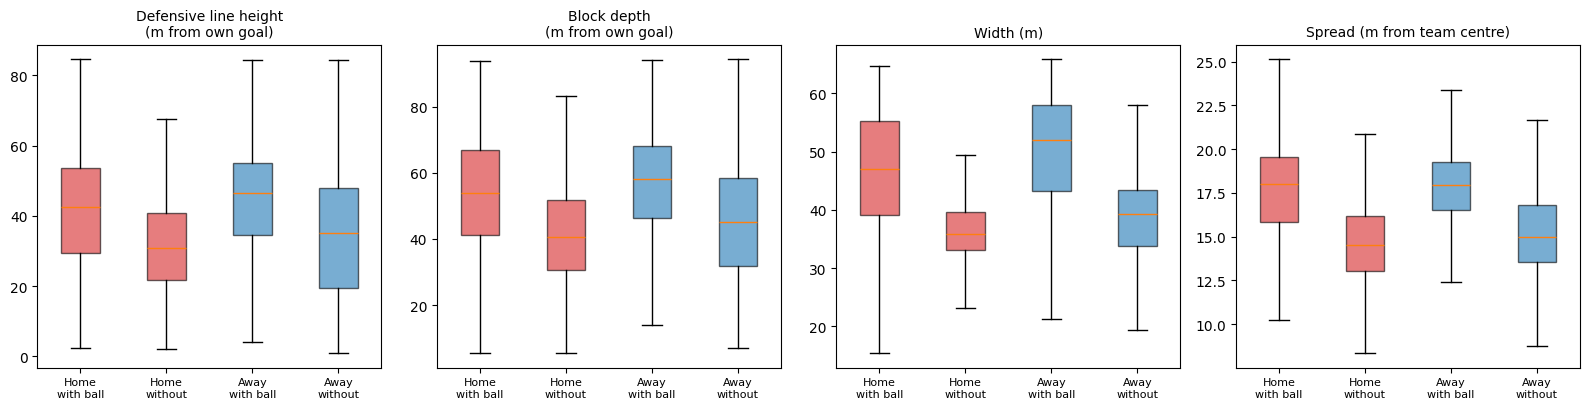

In [3]:
def shape_table(team, ids, gk, own_goal_x):
    outf = [i for i in ids if i != gk]
    X = game[[f"{team}_{i}_x" for i in outf]].values
    Y = game[[f"{team}_{i}_y" for i in outf]].values
    depth = (X - own_goal_x) if team == "Home" else (own_goal_x - X)       # metres from own goal line
    ok = (~np.isnan(X)).sum(axis=1) >= 8                                    # need 8+ outfielders tracked
    Xo, Yo, Do = X[ok], Y[ok], depth[ok]
    cx, cy = np.nanmean(Xo, 1, keepdims=True), np.nanmean(Yo, 1, keepdims=True)
    return pd.DataFrame({
        "length": np.nanmax(Xo, 1) - np.nanmin(Xo, 1),
        "width": np.nanmax(Yo, 1) - np.nanmin(Yo, 1),
        "line_height": np.nanmean(np.sort(Do, 1)[:, :4], 1),               # 4 deepest outfielders
        "block_depth": np.nanmean(Do, 1),                                   # average distance from own goal
        "spread": np.nanmean(np.hypot(Xo - cx, Yo - cy), 1)}, index=game.index[ok])

tables = {}
for team, ids, gk, gx in [("Home", G.home_ids, G.home_gk, -52.5), ("Away", G.away_ids, G.away_gk, 52.5)]:
    t = shape_table(team, ids, gk, gx)
    other = "Away" if team == "Home" else "Home"
    p = poss.reindex(t.index)
    t["state"] = np.select([p == team, p == other], ["in possession", "out of possession"], default="")
    tables[team] = t[t.state != ""]

cols = ["length", "width", "line_height", "block_depth", "spread"]
summary = pd.concat({team: t.groupby("state")[cols].mean().round(1) for team, t in tables.items()})
print(summary.to_string())
print({team: (t.groupby("state").size() / FPS / 60).round(1).to_dict() for team, t in tables.items()})
summary.to_csv(OUT / "shape_by_possession.csv")

metrics = [("line_height", "Defensive line height\n(m from own goal)"), ("block_depth", "Block depth\n(m from own goal)"),
           ("width", "Width (m)"), ("spread", "Spread (m from team centre)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (m, title) in zip(axes, metrics):
    data, labels, colors = [], [], []
    for team, c in [("Home", "tab:red"), ("Away", "tab:blue")]:
        for state in ["in possession", "out of possession"]:
            data.append(tables[team].loc[tables[team].state == state, m].values)
            labels.append(f"{team}\n{'with ball' if state[0] == 'i' else 'without'}"); colors.append(c)
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
    for patch, c in zip(bp["boxes"], colors): patch.set_facecolor(c); patch.set_alpha(.6)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels(labels, fontsize=8); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "shape_by_possession.png", dpi=130); plt.show()

8377 moments sampled


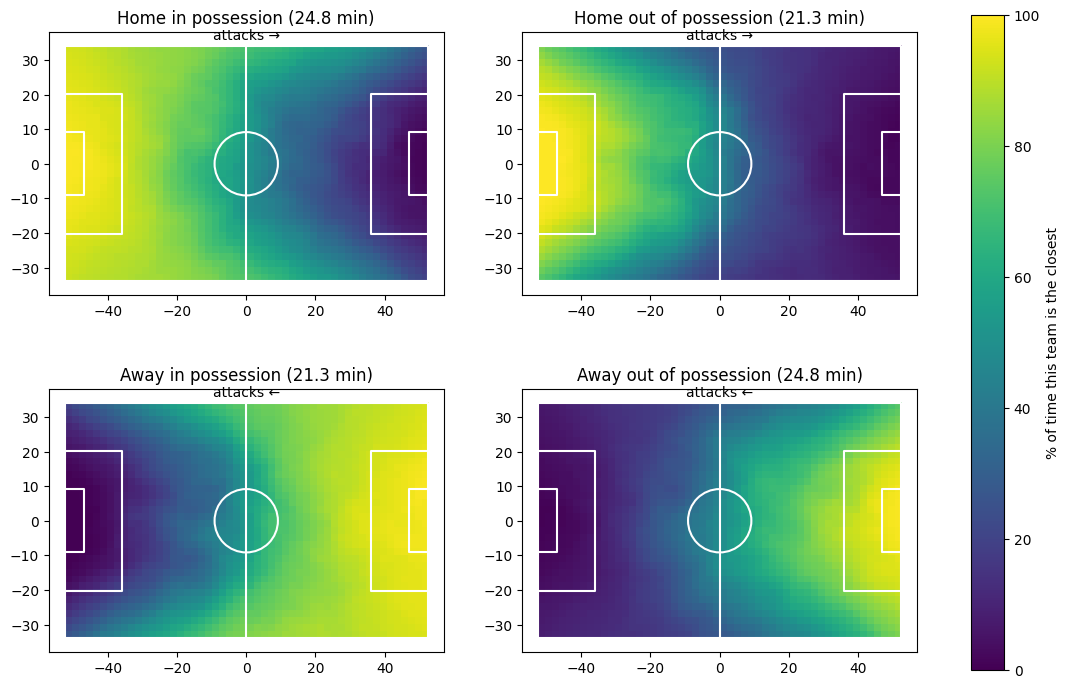

   team              state  minutes  own_control_whole_pitch  own_control_attacking_third  own_control_defensive_third
0  Home      in possession     24.8                       57                           23                           90
1  Home  out of possession     21.3                       42                            8                           80
2  Away      in possession     21.3                       58                           20                           92
3  Away  out of possession     24.8                       43                           10                           77


In [4]:
STEP = 2.0
gx = np.arange(-52.5 + STEP / 2, 52.5, STEP); gy = np.arange(-34 + STEP / 2, 34, STEP)
GX, GY = np.meshgrid(gx, gy); pts = np.c_[GX.ravel(), GY.ravel()]

def nearest(px, py):
    ok = ~np.isnan(px)
    return np.hypot(pts[:, 0, None] - px[ok][None, :], pts[:, 1, None] - py[ok][None, :]).min(axis=1)

sample = game.index[in_play.values][::10]
S = game.loc[sample]
HX = S[[f"Home_{i}_x" for i in G.home_ids]].values; HY = S[[f"Home_{i}_y" for i in G.home_ids]].values
AX = S[[f"Away_{i}_x" for i in G.away_ids]].values; AY = S[[f"Away_{i}_y" for i in G.away_ids]].values

ctrl = np.zeros((len(sample), len(pts)), dtype=np.int8)           # 1 = Home is closer
for k in range(len(sample)):
    ctrl[k] = nearest(HX[k], HY[k]) < nearest(AX[k], AY[k])
poss_s = poss.loc[sample].values
print(len(sample), "moments sampled")

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
rows = []
for r, team in enumerate(["Home", "Away"]):
    other = "Away" if team == "Home" else "Home"
    att = pts[:, 0] > 17.5 if team == "Home" else pts[:, 0] < -17.5          # attacking third
    dfn = pts[:, 0] < -17.5 if team == "Home" else pts[:, 0] > 17.5           # defensive third
    for c, (state, sel) in enumerate([("in possession", poss_s == team), ("out of possession", poss_s == other)]):
        m = ctrl[sel].mean(axis=0); own = m if team == "Home" else 1 - m      # share of time THIS team is closer
        ax = axes[r, c]
        im = ax.imshow(own.reshape(GX.shape) * 100, origin="lower", extent=(-52.5, 52.5, -34, 34),
                       cmap="viridis", vmin=0, vmax=100)
        mio.draw_pitch(ax); ax.set_facecolor("none")
        ax.set_title(f"{team} {state} ({sel.sum() * 10 / FPS / 60:.1f} min)")
        ax.annotate("attacks " + ("→" if team == "Home" else "←"), (0, 36), ha="center", color="k")
        rows.append(dict(team=team, state=state, minutes=round(sel.sum() * 10 / FPS / 60, 1),
                         own_control_whole_pitch=round(own.mean() * 100), own_control_attacking_third=round(own[att].mean() * 100),
                         own_control_defensive_third=round(own[dfn].mean() * 100)))
fig.colorbar(im, ax=axes, label="% of time this team is the closest")
plt.savefig(OUT / "space_control.png", dpi=130, bbox_inches="tight"); plt.show()
control = pd.DataFrame(rows); control.to_csv(OUT / "space_control.csv", index=False); print(control.to_string())

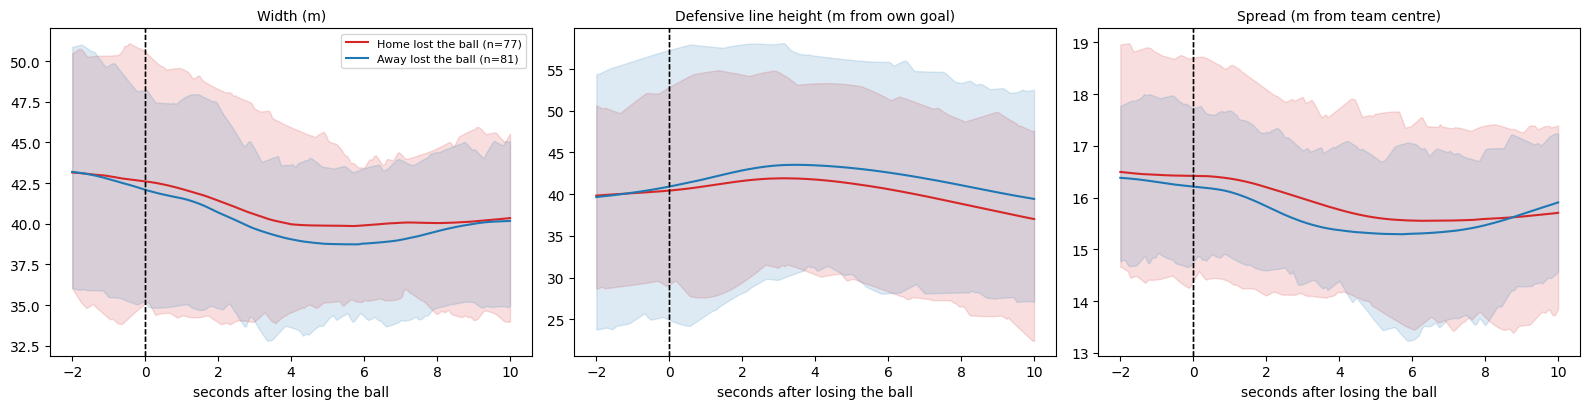

   team       metric   n  t=-2s  t=0s  t=3s  t=6s  t=10s
0  Home        width  77   43.1  42.6  40.6  39.9   40.3
1  Home  line_height  77   39.8  40.4  41.9  40.6   37.0
2  Home       spread  77   16.5  16.4  16.0  15.6   15.7
3  Away        width  81   43.2  42.1  39.7  38.8   40.2
4  Away  line_height  81   39.7  40.9  43.5  42.6   39.4
5  Away       spread  81   16.4  16.2  15.5  15.3   15.9


In [5]:
raw = {team: shape_table(team, ids, gk, gx) for team, ids, gk, gx in
       [("Home", G.home_ids, G.home_gk, -52.5), ("Away", G.away_ids, G.away_gk, 52.5)]}
PRE, POST = 2 * FPS, 10 * FPS
t_axis = np.arange(-PRE, POST + 1) / FPS
lost = events[events.Type == "BALL LOST"]
names = {"width": "Width (m)", "line_height": "Defensive line height (m from own goal)", "spread": "Spread (m from team centre)"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
rows = []
for team, c in [("Home", "tab:red"), ("Away", "tab:blue")]:
    curves = {m: [] for m in names}; used = 0
    for f in [int(x) for x in lost.loc[lost.Team == team, "Start Frame"]]:
        win = np.arange(f - PRE, f + POST + 1)
        if win[0] < game.index.min() or win[-1] > game.index.max(): continue
        if not in_play.reindex(win).all(): continue                 # play must not stop inside the window
        used += 1
        for m in names: curves[m].append(raw[team][m].reindex(win).values)
    for ax, m in zip(axes, names):
        arr = np.array(curves[m])
        mean = np.nanmean(arr, 0)
        ax.plot(t_axis, mean, c=c, label=f"{team} lost the ball (n={used})")
        ax.fill_between(t_axis, np.nanpercentile(arr, 25, 0), np.nanpercentile(arr, 75, 0), color=c, alpha=.15)
        ax.axvline(0, c="k", ls="--", lw=1); ax.set_title(names[m], fontsize=10); ax.set_xlabel("seconds after losing the ball")
        rows.append(dict(team=team, metric=m, n=used, **{f"t={s}s": round(float(mean[PRE + s * FPS]), 1) for s in (-2, 0, 3, 6, 10)}))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "shape_after_turnover.png", dpi=130); plt.show()
res = pd.DataFrame(rows); res.to_csv(OUT / "shape_after_turnover.csv", index=False); print(res.to_string())

## Findings (Metrica Sample Game 1, ball in play only; possession from the events file)
- Live-play split: Home 44%, Away 38%, loose ball 17% (58% of recorded time is live play).
- Without the ball both teams get about 10 m narrower (Home 46.6 -> 36.8 m, Away 50.0 -> 38.6 m), their
  back line drops about 10 m toward their own goal (Home 41.8 -> 31.8 m, Away 43.8 -> 34.1 m) and
  the team bunches up by about 3 m (average distance from team centre).
- Differences between the two teams are small (2-3 m) compared with the spread within each state, so
  they are not treated as real from a single match.
- Space control (nearest-player map): possession is worth about 15 percentage points of the pitch
  (Home 42% -> 57%, Away 43% -> 58%). Even in possession a team owns only 20-23% of its attacking third.
- After losing the ball (77 Home and 81 Away turnovers with no stoppage in the next 10 s), team width
  narrows by about 3-4 m within 4-6 s (Home 42.6 -> 39.9 m, Away 42.1 -> 38.8 m) and spread by about 1 m,
  then partly recovers by 10 s; the defensive line rises 1.5-2.6 m for ~3 s before dropping. The effect is
  small next to turnover-to-turnover variation (IQR about 8 m), so it is a tendency, not a strong result.
  Teams already are narrower at the moment of loss (43 m) than their average in-possession shape (47-50 m).
- Limits: one match; nearest-player control ignores speed and the ball; the possession rule (last
  on-ball event) is approximate; frames sampled every 0.4 s are not independent.